# Türkiye İkinci El Otomobil Fiyatları (2016-2026): Adım Adım Analiz
*Used-car prices in Türkiye (2016-2026): a step-by-step walkthrough*

Bu notebook projenin tamamını adım adım anlatır:

1. Veriyi yükleyip tanımak
2. 10 yıllık piyasa seyri ve kalibrasyon kaynakları
3. Yeni değişkenler: **renk, motor hacmi, donanım, boya/değişen parçalar**
4. Neden log fiyat ve aylık "dönem" değişkenleri?
5. Yorumlanabilir OLS: her değişken fiyatı yüzde kaç etkiliyor?
6. **Kaporta:** hangi parçanın boyası/değişimi ne kadar değer kaybettiriyor? Örnek ekspertiz hesabı
7. Markaya göre yıllık değer kaybı
8. Tahmin modelleri ve özellik önemi
9. Sonuç ve sınırlamalar

> **Önemli:** Veri **sentetiktir**. Ortalama fiyat seyri, renk/yakıt/motor dağılımları kamuya açık kaynaklara
> göre ayarlanmıştır, ama tek tek ilanlar gerçek değildir. Etkilerin büyüklüğünü (ör. tavan değişimi −%11) veriyi
> üretirken biz seçtik. Notebook bu yüzden **yöntemi** gösterir; piyasa hakkında kesin bilgi vermez.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import analysis as A
import generate_data as G

pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
pd.set_option("display.width", 140)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

df = A.load_listings(ROOT / "data" / "listings.csv")
print(f"{len(df):,} ilan, {df.listing_month.min()} - {df.listing_month.max()}, {df.model.nunique()} model, {df.shape[1]} sütun")
df.head(3).T

16,000 ilan, 2016-01 - 2026-10, 18 model, 32 sütun


,0,1,2
listing_id,1,2,3
listing_month,2018-08,2021-01,2019-06
model,Honda Civic,Hyundai i20,Opel Astra
segment,orta,ekonomi,orta
year,2008,2019,2016
km,141300,48200,147200
fuel,Benzin,Benzin,Dizel
engine_cc,1597,1248,1598
gearbox,Manuel,Manuel,Otomatik
trim,Executive+,Jump,Excellence


## 1. Veri şeması

Her satır bir ilan. Zorunlu sütunlar (gerçek bir CSV ile de çalışmak için) `analysis.REQUIRED` içinde;
yeni eklenen sütunlar isteğe bağlıdır ve varsa modele girer:

| Sütun | Açıklama |
|---|---|
| `color` | Renk (Beyaz referans) |
| `engine_cc` | Motor hacmi, cm³ |
| `trim` / `trim_level` | Donanım paketi adı (ör. *Joy/Touch/Icon*) ve seviyesi (Temel / Orta / Üst) |
| 13 kaporta sütunu | `kaput`, `tavan`, `bagaj`, 4 kapı, 4 çamurluk, 2 tampon: *Orijinal / Lokal boyalı / Boyalı / Değişen* |
| `n_painted`, `n_replaced` | Boyalı ve değişen parça sayısı (özet) |
| `body_loss_pct_true` | Yalnızca sentetik veride bilinen "gerçek" kaporta kaybı (%). **Modele girmez**, doğrulama için |

In [2]:
print("Zorunlu:", A.REQUIRED)
print("Kaporta parçaları:", A.BODY_PARTS)
df[["model", "year", "km", "fuel", "engine_cc", "trim", "color", "n_painted", "n_replaced", "price"]].describe(include="all").T.iloc[:, :6]

Zorunlu: ['model', 'year', 'km', 'fuel', 'gearbox', 'damage', 'seller_type', 'city', 'listing_month', 'price']
Kaporta parçaları: ['kaput', 'tavan', 'bagaj', 'sol_on_camurluk', 'sag_on_camurluk', 'sol_on_kapi', 'sag_on_kapi', 'sol_arka_kapi', 'sag_arka_kapi', 'sol_arka_camurluk', 'sag_arka_camurluk', 'on_tampon', 'arka_tampon']


,count,unique,top,freq,mean,std
model,16000,18,Fiat Egea,1759,NaN,NaN
year,"16,000.000",NaN,NaN,NaN,"2,014.579",4.539
km,"16,000.000",NaN,NaN,NaN,"128,507.044","94,918.772"
fuel,16000,4,Dizel,7714,NaN,NaN
engine_cc,"16,000.000",NaN,NaN,NaN,"1,464.007",218.362
trim,16000,40,Touch,1197,NaN,NaN
color,16000,6,Beyaz,7614,NaN,NaN
n_painted,"16,000.000",NaN,NaN,NaN,0.992,1.073
n_replaced,"16,000.000",NaN,NaN,NaN,0.279,0.540
price,"16,000.000",NaN,NaN,NaN,"452,374.812","535,823.614"


## 2. 10 yıllık piyasa seyri ve kalibrasyon

Türkiye'de ikinci el fiyatları 2016'dan bu yana nominal olarak yaklaşık **20 kat** arttı. Üreticide ortalama fiyat
seyri `PRICE_ANCHORS` noktalarına oturtulur. Arada kalan aylar log-doğrusal enterpolasyonla doldurulur:

* **2023-11 ve sonrası:** BETAM / sahibindex aylık raporlarındaki ortalama ilan fiyatları (ör. Kasım 2023: 879.146 TL,
  Haziran 2024: 968.926 TL, Kasım 2025: ~1,086 milyon TL, Haziran 2026: ~1,175 milyon TL).
* **2022-11:** Kasım 2023'teki %76,2 yıllık artıştan geri hesap.
* **2016-2022 diğer noktalar:** kesin bir seri bulunamadı. 2018 kur şoku, 2020 pandemi talebi, 2021 çip krizi,
  Aralık 2021 kur krizi ve Haziran 2022 düzenlemesi (6 ay / 6.000 km kuralı) gibi olaylara göre **yaklaşık** değerler.

In [3]:
anchors = pd.Series(G.PRICE_ANCHORS, name="çapa (TL)")
gen = df.groupby("listing_month").price.mean()
cmp = pd.DataFrame({"çapa (TL)": anchors,
                    "üretilen ort. (±1 ay)": [gen.reindex([str(pd.Period(m, "M") + k) for k in (-1, 0, 1)]).mean() for m in anchors.index]})
cmp["oran"] = cmp.iloc[:, 1] / cmp.iloc[:, 0]
cmp.round(3)

,çapa (TL),üretilen ort. (±1 ay),oran
2016-01,62000,"68,999.632",1.113
2017-01,68000,"69,732.556",1.025
2018-01,78000,"83,629.560",1.072
2018-10,92000,"95,123.172",1.034
2019-06,98000,"101,604.619",1.037
2020-01,110000,"108,757.901",0.989
2020-08,165000,"166,061.700",1.006
2021-01,175000,"179,759.225",1.027
2021-11,270000,"280,628.808",1.039
2022-01,360000,"349,220.757",0.970


Üretilen ortalama, çapaların çoğunda hedefin ±%4'ü içinde. En büyük sapma 2016 başında (+%11): ilk aylarda
yaş/model karışımı biraz farklı, üstelik 2016-2022 çapaları zaten yaklaşık değerler. Kalibrasyon ölçeği
(`PRICE_SCALE`), kaynaklı çapaların olduğu 2023-11 sonrası döneme göre hesaplanır.

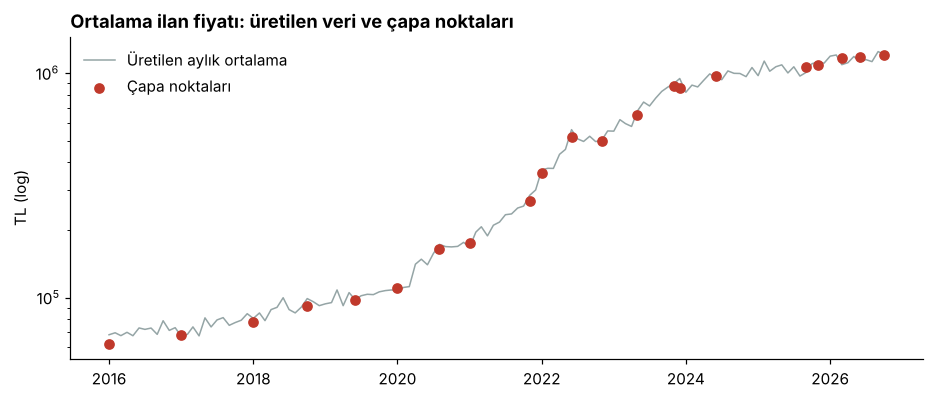

In [4]:
fig, ax = plt.subplots(figsize=(10, 3.8))
x = pd.PeriodIndex(gen.index, freq="M").to_timestamp()
ax.plot(x, gen.values, color="#95a5a6", lw=1, label="Üretilen aylık ortalama")
ax.scatter(pd.PeriodIndex(anchors.index, freq="M").to_timestamp(), anchors.values, color="#c0392b", zorder=5, label="Çapa noktaları")
ax.set_yscale("log"); ax.set_ylabel("TL (log)"); ax.legend(frameon=False)
ax.set_title("Ortalama ilan fiyatı: üretilen veri ve çapa noktaları", loc="left", fontweight="bold");

## 3. Yeni değişkenler

### 3.1 Yakıt, motor hacmi, donanım
* Dizel payı zamanla düşer, hibrit payı 2023 sonrası artar. LPG, benzinli araçlara sonradan dönüşüm olarak eklenir
  (eski ve ekonomi segmentinde daha yaygın, premium ve hibritte yok).
* Motor hacimleri modelin gerçek seçeneklerinden seçilir. ÖTV dilimleri nedeniyle büyük çoğunluk **1.600 cm³ ve altı**.
* Donanım üç seviyeli. Premium modellerde üst paket daha yaygın.

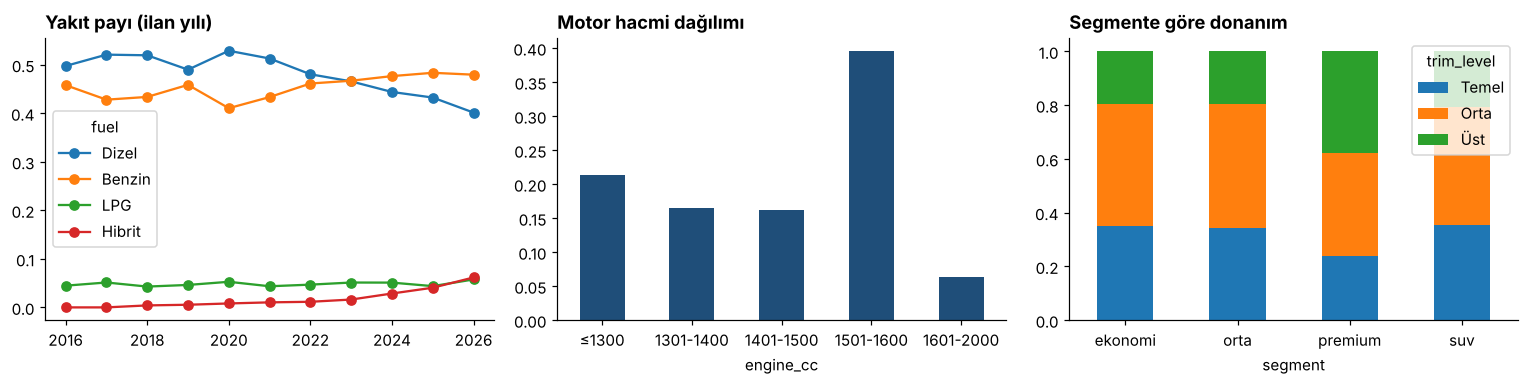

In [5]:
yr = df.listing_month.str[:4]
fuel_share = pd.crosstab(yr, df.fuel, normalize="index")[["Dizel", "Benzin", "LPG", "Hibrit"]]
cc_bins = pd.cut(df.engine_cc, [0, 1300, 1400, 1500, 1600, 2000], labels=["≤1300", "1301-1400", "1401-1500", "1501-1600", "1601-2000"])

fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
fuel_share.plot(ax=axes[0], marker="o"); axes[0].set_title("Yakıt payı (ilan yılı)", loc="left", fontweight="bold"); axes[0].set_xlabel("")
cc_bins.value_counts(normalize=True).sort_index().plot.bar(ax=axes[1], color="#1f4e79"); axes[1].set_title("Motor hacmi dağılımı", loc="left", fontweight="bold")
pd.crosstab(df.segment, df.trim_level, normalize="index")[["Temel", "Orta", "Üst"]].plot.bar(ax=axes[2], stacked=True)
axes[2].set_title("Segmente göre donanım", loc="left", fontweight="bold")
for ax in axes[1:]: ax.tick_params(axis="x", rotation=0)
plt.tight_layout()

### 3.2 Renk
TÜİK'in trafiğe kayıt verilerinde beyazın payı 2018'de %55,6 iken 2023'te ~%29'a düştü. 2026'nın ilk yarısında gri
açık ara birinci. Üretici renk olasılığını **model yılına** bağlar: eski araçlarda beyaz, yenilerde gri ağırlıklı.

In [6]:
pd.crosstab(df.year.clip(2008, 2024), df.color, normalize="index")[G.COLORS].iloc[::4].round(2)

color,Beyaz,Gri,Siyah,Kırmızı,Mavi,Diğer
year,,,,,,
2008,0.550,0.160,0.130,0.050,0.050,0.060
2012,0.520,0.190,0.150,0.050,0.050,0.040
2016,0.460,0.230,0.140,0.060,0.050,0.060
2020,0.410,0.290,0.120,0.050,0.070,0.050
2024,0.310,0.380,0.110,0.060,0.070,0.060


### 3.3 Boya / değişen parçalar (ekspertiz)
Her aracın 13 kaporta parçası için ekspertiz durumu tutulur. Üretim mantığı:

1. Araç yaşı ve km arttıkça "olay" (çizik, sürtme, kaza) sayısı artar (Poisson).
2. Her olay bir parçaya isabet eder: tamponlar ve ön çamurluklar sık, **tavan çok nadir**.
3. Parça lokal boyalı, boyalı ya da değişen olur. Aynı parçaya ikinci olay gelirse ağır olan durum kalır.
4. Ciddi kaporta işlemi olan araçların çoğunda **tramer (sigorta hasar) kaydı** da vardır.

In [7]:
age = A.listing_age(df)
work = df.n_painted + df.n_replaced
print(f"Hiç boya/değişen olmayan ('hatasız') ilan payı: %{(work == 0).mean() * 100:.1f}")
print(f"Tramer kaydı payı: %{df.damage.mean() * 100:.1f}")
pd.DataFrame({
    "ort. boyalı parça": df.n_painted.groupby(pd.cut(age, [-1, 2, 5, 10, 20])).mean(),
    "ort. değişen parça": df.n_replaced.groupby(pd.cut(age, [-1, 2, 5, 10, 20])).mean(),
    "hatasız payı": (work == 0).groupby(pd.cut(age, [-1, 2, 5, 10, 20])).mean(),
}).rename_axis("yaş aralığı")

Hiç boya/değişen olmayan ('hatasız') ilan payı: %32.0
Tramer kaydı payı: %33.2


,ort. boyalı parça,ort. değişen parça,hatasız payı
yaş aralığı,,,
"(-1, 2]",0.353,0.102,0.630
"(2, 5]",0.698,0.190,0.411
"(5, 10]",1.182,0.331,0.205
"(10, 20]",1.838,0.534,0.075


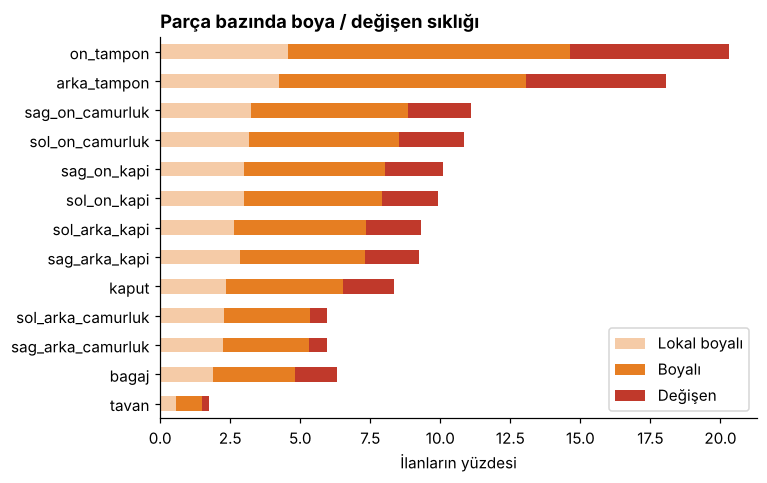

In [8]:
freq = pd.DataFrame({s: (df[A.BODY_PARTS] == s).mean() * 100 for s in A.STATE_KEYS}).sort_values("Boyalı")
freq.plot.barh(stacked=True, figsize=(7, 4.5), color=["#f5cba7", "#e67e22", "#c0392b"])
plt.xlabel("İlanların yüzdesi"); plt.title("Parça bazında boya / değişen sıklığı", loc="left", fontweight="bold");

Veriye kurulan parça cezaları (`generate_data.BODY_PENALTY`, log fiyat; lokal boya = boyalının %40'ı). Parça bazlı
resmi bir yüzde tablosu yok. Sıralamayı ekspertiz pratiğine göre seçtik: **tavan** (yapısal hasar / devrilme şüphesi)
ve kaynaklı **arka çamurluk** en ağır, cıvatalı ön çamurluk hafif, plastik **tampon** neredeyse önemsiz. Büyüklükler,
hukuk sitelerindeki değer kaybı tablolarında geçen aralıklarla (ör. kapı değişimi için %5-12) uyumlu tutuldu.

In [9]:
pen = pd.DataFrame(G.BODY_PENALTY).T
pen.insert(0, "Lokal boyalı", G.LOCAL_SHARE * pen["Boyalı"])
(-np.expm1(-pen) * 100).round(1).rename(index=A.REGION_LABELS).add_suffix(" (% kayıp)")

,Lokal boyalı (% kayıp),Boyalı (% kayıp),Değişen (% kayıp)
Tavan,2.400,5.800,11.300
Arka çamurluk,1.200,3.000,6.800
Kaput,1.000,2.500,4.400
Kapı,0.600,1.500,2.500
Bagaj kapağı,0.600,1.500,3.000
Ön çamurluk,0.500,1.200,2.000
Tampon,0.100,0.300,0.500


## 4. Neden log fiyat ve aylık dönem değişkenleri?

* **Log fiyat:** Etkiler çarpımsal: tavan değişimi 300 bin TL'lik araçta da 3 milyon TL'lik araçta da yaklaşık aynı
  *yüzdeyi* götürür. Log ölçekte katsayı `b` doğrudan `exp(b) − 1` yüzde etkiye çevrilir.
* **Ay kuklaları:** Fiyat seviyesi 10 yılda ~20 kat ve doğrusal olmayan biçimde değişti (2022'de bir yılda ikiye
  katlandı, 2022 ortasında geriledi). Tek bir "ay" eğimi bunu yakalayamaz. Her ay için ayrı bir kukla değişken,
  OLS'e kompozisyondan arındırılmış bir **piyasa endeksi** kestirtir.
* **Yaş = ilan yılı − model yılı:** İlanlar 11 yıla yayıldığı için sabit bir referans yıl kullanılmaz.

In [10]:
months = sorted(df.listing_month.unique())
X = A.build_features(df, month_order=months, time_mode="dummies", age_by_model=True)
y = np.log(df.price.to_numpy(float))
groups = A.feature_groups(X.columns)
print(f"Özellik matrisi: {X.shape[0]:,} x {X.shape[1]}")
pd.Series({k: len(v) for k, v in groups.items()}, name="sütun sayısı").sort_values(ascending=False)

Özellik matrisi: 16,000 x 209


ilan dönemi               129
kaporta (boya/değişen)     21
yaş                        19
model                      17
şehir                       8
renk                        5
yakıt                       3
donanım                     2
km                          1
motor hacmi                 1
tramer kaydı                1
satıcı tipi                 1
vites                       1
Name: sütun sayısı, dtype: int64

## 5. Yorumlanabilir OLS: "diğer her şey sabitken" etkiler

Sentetik verinin avantajı: gerçek etkileri biliyoruz. OLS'in %95 güven aralığı bunları kapsıyor mu?

In [11]:
table = A.fit_ols(A.drop_constant(X), y)
planted = dict(G.TRUE_EFFECTS)
rows = []
for col, v in planted.items():
    r = table.loc[col]
    rows.append(dict(değişken=col, ols_yüzde=A.pct_effect(r.coef) * 100, ga_alt=A.pct_effect(r.ci_low) * 100,
                     ga_üst=A.pct_effect(r.ci_high) * 100, gerçek_yüzde=A.pct_effect(v) * 100,
                     kapsıyor=r.ci_low <= v <= r.ci_high))
eff = pd.DataFrame(rows)
print(f"Kapsanan: {eff.kapsıyor.sum()}/{len(eff)}")
eff.round(2)

Kapsanan: 18/18


,değişken,ols_yüzde,ga_alt,ga_üst,gerçek_yüzde,kapsıyor
0,fuel_Dizel,4.220,3.890,4.550,4.080,True
1,fuel_Hibrit,7.160,5.910,8.420,7.250,True
2,fuel_LPG,-5.670,-6.240,-5.090,-5.820,True
3,gearbox_Otomatik,8.310,7.990,8.630,8.330,True
4,damage,-4.780,-5.090,-4.480,-4.880,True
5,seller_Galeri,3.580,3.320,3.840,3.560,True
6,city_İstanbul,1.880,1.530,2.220,2.020,True
7,city_Ankara,1.180,0.740,1.610,1.010,True
8,city_İzmir,1.350,0.860,1.840,1.010,True
9,km_10k,-0.580,-0.600,-0.560,-0.600,True


Okuma örnekleri (OLS tahminleri):
* **Üst donanım** temel pakete göre yaklaşık **+%9**, **orta donanım** ~+%4.
* Aynı model içinde **+100 cm³** motor hacmi ~+%2,5.
* **Renk:** gri, beyaza göre biraz primli. Kırmızı, mavi ve "diğer" renkler %2-4 iskontolu (daha dar alıcı kitlesi).
* **Tramer kaydı**, boya/değişen parçalara **ek olarak** ~−%5. Kaporta etkileri ayrıca modelde.

## 6. Kaporta: hangi parça ne kadar değer kaybettiriyor?

13 parça, analizde 7 bölgeye toplanır (ör. 4 kapı → `kapi`). Her bölge ve işlem türü için özellik = o durumdaki
parça **sayısı**. Böylece katsayı "bir parça daha boyalı olursa" etkisidir.

In [12]:
body = A.body_effects(table)
_, planted_body = __import__("run_analysis").planted_effects()
body["gerçek_yüzde"] = body.variable.map(lambda v: A.pct_effect(planted_body[v]) * 100)
body["kapsıyor"] = [table.loc[v, "ci_low"] <= planted_body[v] <= table.loc[v, "ci_high"] for v in body.variable]
show = body.assign(ols_yüzde=body.pct_effect * 100, ga_alt=body.pct_low * 100, ga_üst=body.pct_high * 100)
print(f"Kapsanan: {show.kapsıyor.sum()}/{len(show)}")
show[["region_label", "state", "ols_yüzde", "ga_alt", "ga_üst", "gerçek_yüzde", "kapsıyor"]].sort_values("ols_yüzde").round(2)

Kapsanan: 21/21


,region_label,state,ols_yüzde,ga_alt,ga_üst,gerçek_yüzde,kapsıyor
5,Tavan,Değişen,-10.360,-12.700,-7.950,-11.310,True
17,Arka çamurluk,Değişen,-6.410,-7.480,-5.330,-6.760,True
4,Tavan,Boyalı,-5.290,-6.510,-4.050,-5.820,True
2,Kaput,Değişen,-4.370,-5.270,-3.460,-4.400,True
8,Bagaj kapağı,Değişen,-3.140,-4.150,-2.120,-2.960,True
16,Arka çamurluk,Boyalı,-2.730,-3.240,-2.220,-2.960,True
1,Kaput,Boyalı,-2.540,-3.160,-1.910,-2.470,True
3,Tavan,Lokal boyalı,-2.290,-3.940,-0.620,-2.370,True
11,Ön çamurluk,Değişen,-2.130,-2.730,-1.530,-1.980,True
14,Kapı,Değişen,-2.060,-2.510,-1.610,-2.470,True


In [13]:
pv = show.pivot(index="region_label", columns="state", values="ols_yüzde")[["Lokal boyalı", "Boyalı", "Değişen"]]
pv = pv.loc[pv["Değişen"].sort_values().index]
ax = pv.plot.barh(figsize=(8, 4.2), color=["#f5cba7", "#e67e22", "#c0392b"])
ax.axvline(0, color="black", lw=0.8); ax.set_xlabel("Tek parça için fiyat etkisi (%)"); ax.set_ylabel("")
ax.set_title("OLS: bölge ve işlem türüne göre değer kaybı", loc="left", fontweight="bold");

### 6.1 Örnek ekspertiz raporu → TL cinsinden kayıp
`body_loss_breakdown`, bir aracın ekspertiz sonucunu parça parça değer kaybına çevirir. Aşağıdaki araç:
tavan boyalı, sol arka çamurluk değişen, iki kapı boyalı, ön tampon değişen.

In [14]:
rapor = {"tavan": "Boyalı", "sol_arka_camurluk": "Değişen", "sol_on_kapi": "Boyalı", "sol_arka_kapi": "Boyalı",
         "on_tampon": "Değişen", "kaput": "Orijinal"}
temiz_fiyat = 1_200_000  # aynı aracın hatasız hali (TL)
bd = A.body_loss_breakdown(rapor, body)
bd["TL"] = temiz_fiyat * bd.pct_effect  # parça satırları: yalnız o parça işlem görmüş olsaydı kayıp
bd.assign(yüzde=bd.pct_effect * 100).round({"yüzde": 2, "TL": -2})[["part", "state", "yüzde", "TL"]]

,part,state,yüzde,TL
0,tavan,Boyalı,-5.290,"-63,500.000"
1,sol_arka_camurluk,Değişen,-6.410,"-77,000.000"
2,sol_on_kapi,Boyalı,-1.680,"-20,100.000"
3,sol_arka_kapi,Boyalı,-1.680,"-20,100.000"
4,on_tampon,Değişen,-0.800,"-9,600.000"
5,TOPLAM,,-14.990,"-179,900.000"


Etkiler log ölçekte toplandığı için toplam kayıp, parça yüzdelerinin basit toplamından biraz küçüktür
(`exp(Σb) − 1`). Gerçek veride bu tablo, ekspertiz raporlu ilanlarla aynı kodla kestirilebilir.

## 7. Markaya göre yıllık değer kaybı
Her model için ayrı yaş eğimi (`age_by_model=True`). Bu etkileşim olmadan, değerini iyi koruyan modellerde yoğunlaşan
değişkenlerin (ör. hibrit: Toyota/Honda) katsayıları yanlı çıkıyordu. Etkileşim eklenince tüm kurulan etkiler
güven aralığı içinde bulundu.

In [15]:
dep = A.model_depreciation(table, sorted(df.model.unique()))
dep["gerçek_%"] = dep.model.map(lambda m: -np.expm1(-G.MODELS[m]["dep"]) * 100)
dep.assign(ols_yıllık_kayıp_yüzde=dep.annual_loss_pct * 100)[["model", "ols_yıllık_kayıp_yüzde", "gerçek_%"]].round(2)

,model,ols_yıllık_kayıp_yüzde,gerçek_%
0,Honda Civic,4.490,4.400
1,Toyota Corolla,4.530,4.400
2,Dacia Duster,4.960,4.880
3,Toyota C-HR,5.060,4.880
4,Fiat Egea,5.080,4.880
5,Volkswagen Polo,5.320,5.350
6,Renault Clio,5.400,5.350
7,Hyundai i20,5.430,5.350
8,Hyundai Tucson,5.910,5.820
9,Skoda Octavia,5.960,5.820


## 8. Piyasa endeksi: ham ortalama vs OLS
Ham aylık ortalama fiyat, o ay hangi araçların ilana çıktığına (yaş, model karışımı) bağlıdır. OLS'in ay kuklaları
ise "aynı araç bu ay ne kadar?" sorusunu cevaplar.

In [16]:
idx_ols = A.period_index(table, months)
raw = gen.reindex(months) / gen.iloc[0]
true_idx = G.market_index().reindex(months)
fig, ax = plt.subplots(figsize=(10, 3.8))
x = pd.PeriodIndex(months, freq="M").to_timestamp()
ax.plot(x, raw, color="#95a5a6", lw=1, label="Ham ortalama")
ax.plot(x, idx_ols, color="#1f4e79", lw=2, label="OLS ay etkileri")
ax.plot(x, true_idx / true_idx.iloc[0], color="#c0392b", ls="--", lw=1.2, label="Kurulan gerçek endeks")
ax.set_yscale("log"); ax.legend(frameon=False); ax.set_title("Piyasa endeksi (2016-01 = 1)", loc="left", fontweight="bold")
err = (np.log(idx_ols) - np.log(true_idx / true_idx.iloc[0])).abs()
print(f"OLS endeksi gerçek endeksten ortalama {err.mean() * 100:.1f} log-puan sapıyor.")

OLS endeksi gerçek endeksten ortalama 0.8 log-puan sapıyor.


## 9. Tahmin modelleri ve özellik önemi
Tahmin amacıyla OLS'i Gradient Boosting ve basit bir referansla (aynı model + aynı ilan yılı medyanı)
karşılaştırıyoruz. Tam karşılaştırma (Random Forest ve 5-katlı çapraz doğrulama dahil) `run_analysis.py` içinde.

In [17]:
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import train_test_split
import run_analysis as R

Xn = A.build_features(df, month_order=months, time_mode="numeric")
tr, te = train_test_split(np.arange(len(df)), test_size=0.2, random_state=0)
ols_tr = A.fit_ols(A.drop_constant(X.iloc[tr]), y[tr])
gb = HistGradientBoostingRegressor(max_iter=800, learning_rate=0.05, max_leaf_nodes=31, l2_regularization=1.0, random_state=0).fit(Xn.iloc[tr], y[tr])
price_te = np.exp(y[te])
preds = {
    "Referans (model+yıl medyanı)": R.baseline_predict(df.iloc[tr], pd.Series(np.exp(y[tr]), index=df.index[tr]), df.iloc[te]),
    "OLS (log-lineer)": np.exp(A.ols_predict(ols_tr, X.iloc[te])),
    "Gradient Boosting": np.exp(gb.predict(Xn.iloc[te])),
}
pd.DataFrame({k: R.score(price_te, v) for k, v in preds.items()}).T.assign(MAPE=lambda d: d.MAPE * 100, MedAPE=lambda d: d.MedAPE * 100).round(3)

,MAPE,MedAPE,MAE_TL,R2
Referans (model+yıl medyanı),19.958,16.548,"94,067.812",0.878
OLS (log-lineer),6.591,5.519,"30,041.689",0.987
Gradient Boosting,7.646,6.313,"36,336.172",0.979


Bu veride OLS en iyi sonucu veriyor, çünkü veri log-lineer bir yapıyla üretildi ve OLS doğru kurulmuş durumda.
Gradient Boosting yine de referansın çok önünde. Ayrıca OLS'te bilerek modellenmeyen **çip krizi primini**
(2021 ortası-2022 sonu, 0-1 yaşındaki araçlar +%6) yakalayabilir. Gerçek ilan verisinde etkileşimler ve eksik
bilgiler arttıkça ağaç modellerinin göreli avantajı büyük olasılıkla artar; bu projede test edilmedi.

In [18]:
imp = A.grouped_permutation_importance(lambda Z: A.ols_predict(ols_tr, Z), X.iloc[te], y[te], n_repeats=5, seed=0)
ax = imp.iloc[::-1].plot.barh(x="variable", y="rmse_increase", xerr="std", legend=False, figsize=(7, 4.5), color="#1f4e79")
ax.set_xlabel("Karıştırınca log-RMSE artışı"); ax.set_ylabel("")
ax.set_title("Özellik önemi (OLS, test seti)", loc="left", fontweight="bold")
imp.round(4)

,variable,rmse_increase,std
0,ilan dönemi,1.482,0.019
1,model,0.444,0.004
2,yaş,0.152,0.002
3,motor hacmi,0.030,0.001
4,km,0.027,0.001
5,vites,0.017,0.001
6,donanım,0.012,0.001
7,yakıt,0.009,0.000
8,tramer kaydı,0.006,0.000
9,kaporta (boya/değişen),0.005,0.000


**Okuma:** Fiyat farklarının çoğunu **ilan dönemi** (enflasyon), **model** ve **yaş** açıklıyor. Kaporta, renk ve
şehir tek tek küçük ama sistematik etkiler. Kaporta tüm ilanlarda değil, işlem görmüş araçlarda etkili olduğu için
ortalama önemi düşük görünüyor. Ancak tavanı değişmiş bir araç için tek başına %10'un üzerinde fark yaratıyor.

## 10. Sonuç ve sınırlamalar

* Yöntem, bilinen etkileri geri buluyor: genel etkiler, 21 kaporta etkisi ve aylık piyasa endeksi kurulan değerlere çok yakın.
* **Sentetik veri:** Etkilerin büyüklüğü bizim seçimimiz. Bulgular piyasa hakkında kesin bilgi vermez.
* 2016-2022 fiyat çapaları yaklaşık değerler. EV'ler (ör. Togg, Tesla) ve ağır hasar kaydı bu sürümde yok.
* Rastgele eğitim/test ayrımı. Geleceğe tahmin için zamana göre ayrım gerekir.
* Gerçek veride "boya fiyatı %X düşürür" ifadesi nedensel okunmamalı: boyalı araçlar başka açılardan da (bakım, kullanım) farklı olabilir.